# ECG Dataset Analysis

This notebook will inspect the ECG image dataset and summarize class distribution.

# ECG Dataset Analysis

This notebook performs the initial analysis of the ECG dataset.

Objectives:
- Inspect dataset structure
- Count images per class
- Check image dimensions
- Visualize class distribution
- Display sample ECG images
- Create stratified train/validation split
- Preserve the original test set
- Save `train.csv`, `val.csv`, and `test.csv`

In [3]:
from pathlib import Path
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split

import os
import random

In [4]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)

Random seed: 42


In [5]:
PROJECT_ROOT = Path("..").resolve()

DATASET_ROOT = PROJECT_ROOT / "ECG_DATA"
TRAIN_ROOT = DATASET_ROOT / "train"
TEST_ROOT = DATASET_ROOT / "test"

SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Train path:", TRAIN_ROOT)
print("Test path:", TEST_ROOT)
print("Split output path:", SPLIT_DIR)

Project root: E:\Academia\archive\ECG_MI_Project
Train path: E:\Academia\archive\ECG_MI_Project\ECG_DATA\train
Test path: E:\Academia\archive\ECG_MI_Project\ECG_DATA\test
Split output path: E:\Academia\archive\ECG_MI_Project\data\splits


In [6]:
print("Dataset root exists:", DATASET_ROOT.exists())
print("Train folder exists:", TRAIN_ROOT.exists())
print("Test folder exists:", TEST_ROOT.exists())

Dataset root exists: True
Train folder exists: True
Test folder exists: True


In [7]:
CLASS_FOLDER_MAP = {
    "ECG Images of Myocardial Infarction Patients": "MI",
    "ECG Images of Patient that have abnormal heartbeat": "Abnormal",
    "ECG Images of Patient that have History of MI": "History_MI",
    "Normal Person ECG Images": "Normal",
}

CLASS_TO_LABEL = {
    "MI": 0,
    "Abnormal": 1,
    "History_MI": 2,
    "Normal": 3,
}

LABEL_TO_CLASS = {v: k for k, v in CLASS_TO_LABEL.items()}

print(CLASS_TO_LABEL)

{'MI': 0, 'Abnormal': 1, 'History_MI': 2, 'Normal': 3}


In [8]:
print("TRAIN folders:")
for folder in TRAIN_ROOT.iterdir():
    if folder.is_dir():
        print("-", folder.name)

print("\nTEST folders:")
for folder in TEST_ROOT.iterdir():
    if folder.is_dir():
        print("-", folder.name)

TRAIN folders:
- ECG Images of Myocardial Infarction Patients (240x12=2880)
- ECG Images of Patient that have abnormal heartbeat (233x12=2796)
- ECG Images of Patient that have History of MI (172x12=2064)
- Normal Person ECG Images (284x12=3408)

TEST folders:
- ECG Images of Myocardial Infarction Patients (240x12=2880)
- ECG Images of Patient that have abnormal heartbeat (233x12=2796)
- ECG Images of Patient that have History of MI (172x12=2064)
- Normal Person ECG Images (284x12=3408)


In [9]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

In [14]:
def find_class_dir(root_dir, folder_key):
    matches = [
        path for path in root_dir.iterdir()
        if path.is_dir() and folder_key in path.name
    ]

    if not matches:
        raise FileNotFoundError(f"No folder matched '{folder_key}' inside {root_dir}")

    return matches[0]


def build_dataframe(root_dir, split_name):
    records = []

    for folder_name, class_name in CLASS_FOLDER_MAP.items():
        class_dir = find_class_dir(root_dir, folder_name)

        for image_path in class_dir.rglob("*"):
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "image_path": str(image_path.resolve()),
                    "label": CLASS_TO_LABEL[class_name],
                    "class_name": class_name,
                    "original_split": split_name
                })

    return pd.DataFrame(records)


In [15]:
train_full_df = build_dataframe(TRAIN_ROOT, "train")
test_df = build_dataframe(TEST_ROOT, "test")

print("Train images:", len(train_full_df))
print("Test images:", len(test_df))

Train images: 3023
Test images: 928


In [16]:
train_full_df.head()

,image_path,label,class_name,original_split
0,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,0,MI,train
1,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,0,MI,train
2,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,0,MI,train
3,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,0,MI,train
4,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,0,MI,train


In [17]:
train_counts = (
    train_full_df["class_name"]
    .value_counts()
    .reindex(CLASS_TO_LABEL.keys())
)

print(train_counts)

class_name
MI            956
Abnormal      699
History_MI    516
Normal        852
Name: count, dtype: int64


In [18]:
test_counts = (
    test_df["class_name"]
    .value_counts()
    .reindex(CLASS_TO_LABEL.keys())
)

print(test_counts)

class_name
MI            239
Abnormal      233
History_MI    172
Normal        284
Name: count, dtype: int64


In [19]:
distribution_df = pd.DataFrame({
    "Train": train_counts,
    "Test": test_counts
})

distribution_df["Total"] = (
    distribution_df["Train"] +
    distribution_df["Test"]
)

distribution_df

,Train,Test,Total
class_name,,,
MI,956,239,1195
Abnormal,699,233,932
History_MI,516,172,688
Normal,852,284,1136


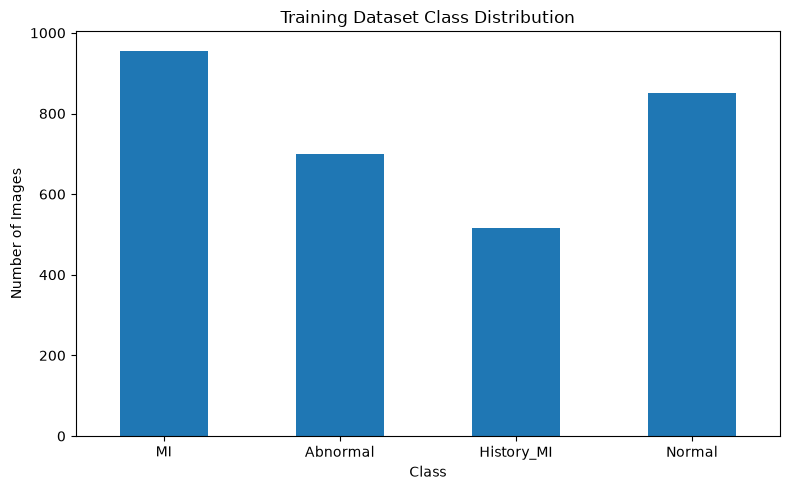

In [20]:
plt.figure(figsize=(8, 5))

train_counts.plot(kind="bar")

plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

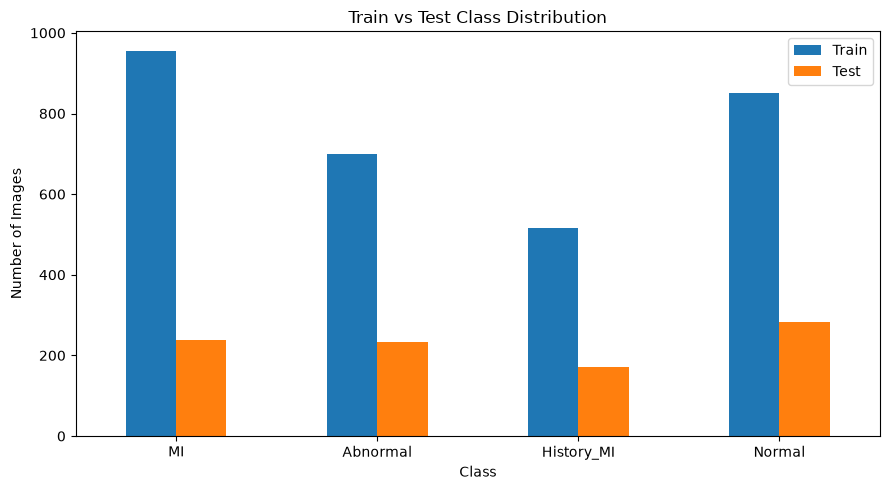

In [21]:
distribution_df[["Train", "Test"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Train vs Test Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [22]:
def inspect_dimensions(df, sample_size=500):
    sample_size = min(sample_size, len(df))

    sampled_df = df.sample(
        n=sample_size,
        random_state=SEED
    )

    dimensions = []

    for image_path in sampled_df["image_path"]:

        try:
            with Image.open(image_path) as img:
                dimensions.append(img.size)

        except Exception as e:
            print("Error:", image_path, e)

    return Counter(dimensions)

In [23]:
dimension_counts = inspect_dimensions(
    train_full_df,
    sample_size=500
)

print("Most common image dimensions:")

for dimension, count in dimension_counts.most_common(10):
    print(dimension, "->", count)

Most common image dimensions:
(2213, 1572) -> 500


In [24]:
def check_all_dimensions(df):
    dimensions = Counter()
    failed_files = []

    for image_path in df["image_path"]:

        try:
            with Image.open(image_path) as img:
                dimensions[img.size] += 1

        except Exception:
            failed_files.append(image_path)

    return dimensions, failed_files


all_dimensions, failed_files = check_all_dimensions(
    pd.concat(
        [train_full_df, test_df],
        ignore_index=True
    )
)

print("Dimensions:")
for dimension, count in all_dimensions.items():
    print(dimension, count)

print("\nFailed files:", len(failed_files))

Dimensions:
(2213, 1572) 3951

Failed files: 0


In [25]:
extension_counts = (
    train_full_df["image_path"]
    .apply(lambda x: Path(x).suffix.lower())
    .value_counts()
)

extension_counts

image_path
.jpg    3023
Name: count, dtype: int64

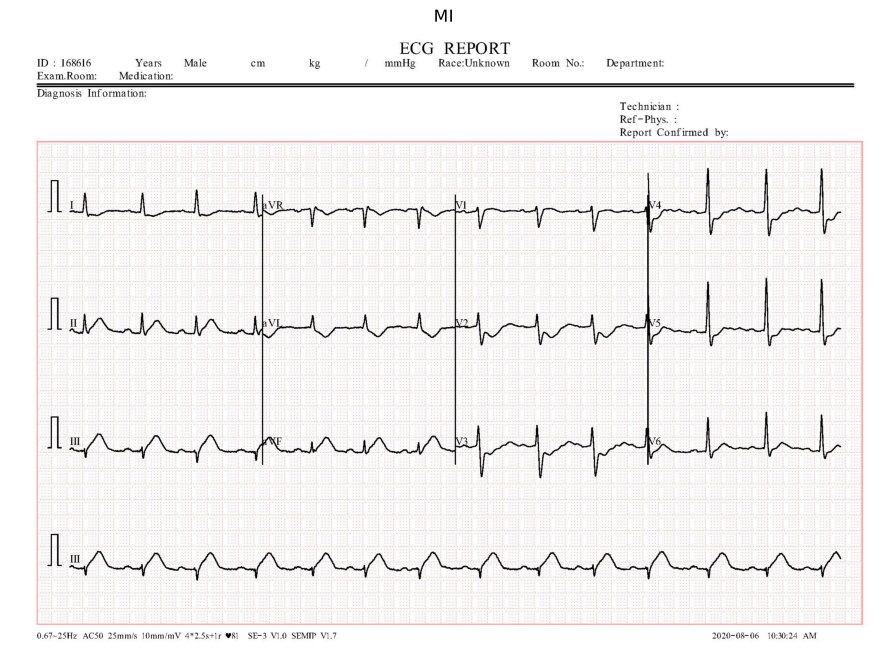

In [26]:
sample_path = train_full_df.iloc[0]["image_path"]

with Image.open(sample_path) as img:
    plt.figure(figsize=(14, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.title(train_full_df.iloc[0]["class_name"])
    plt.show()

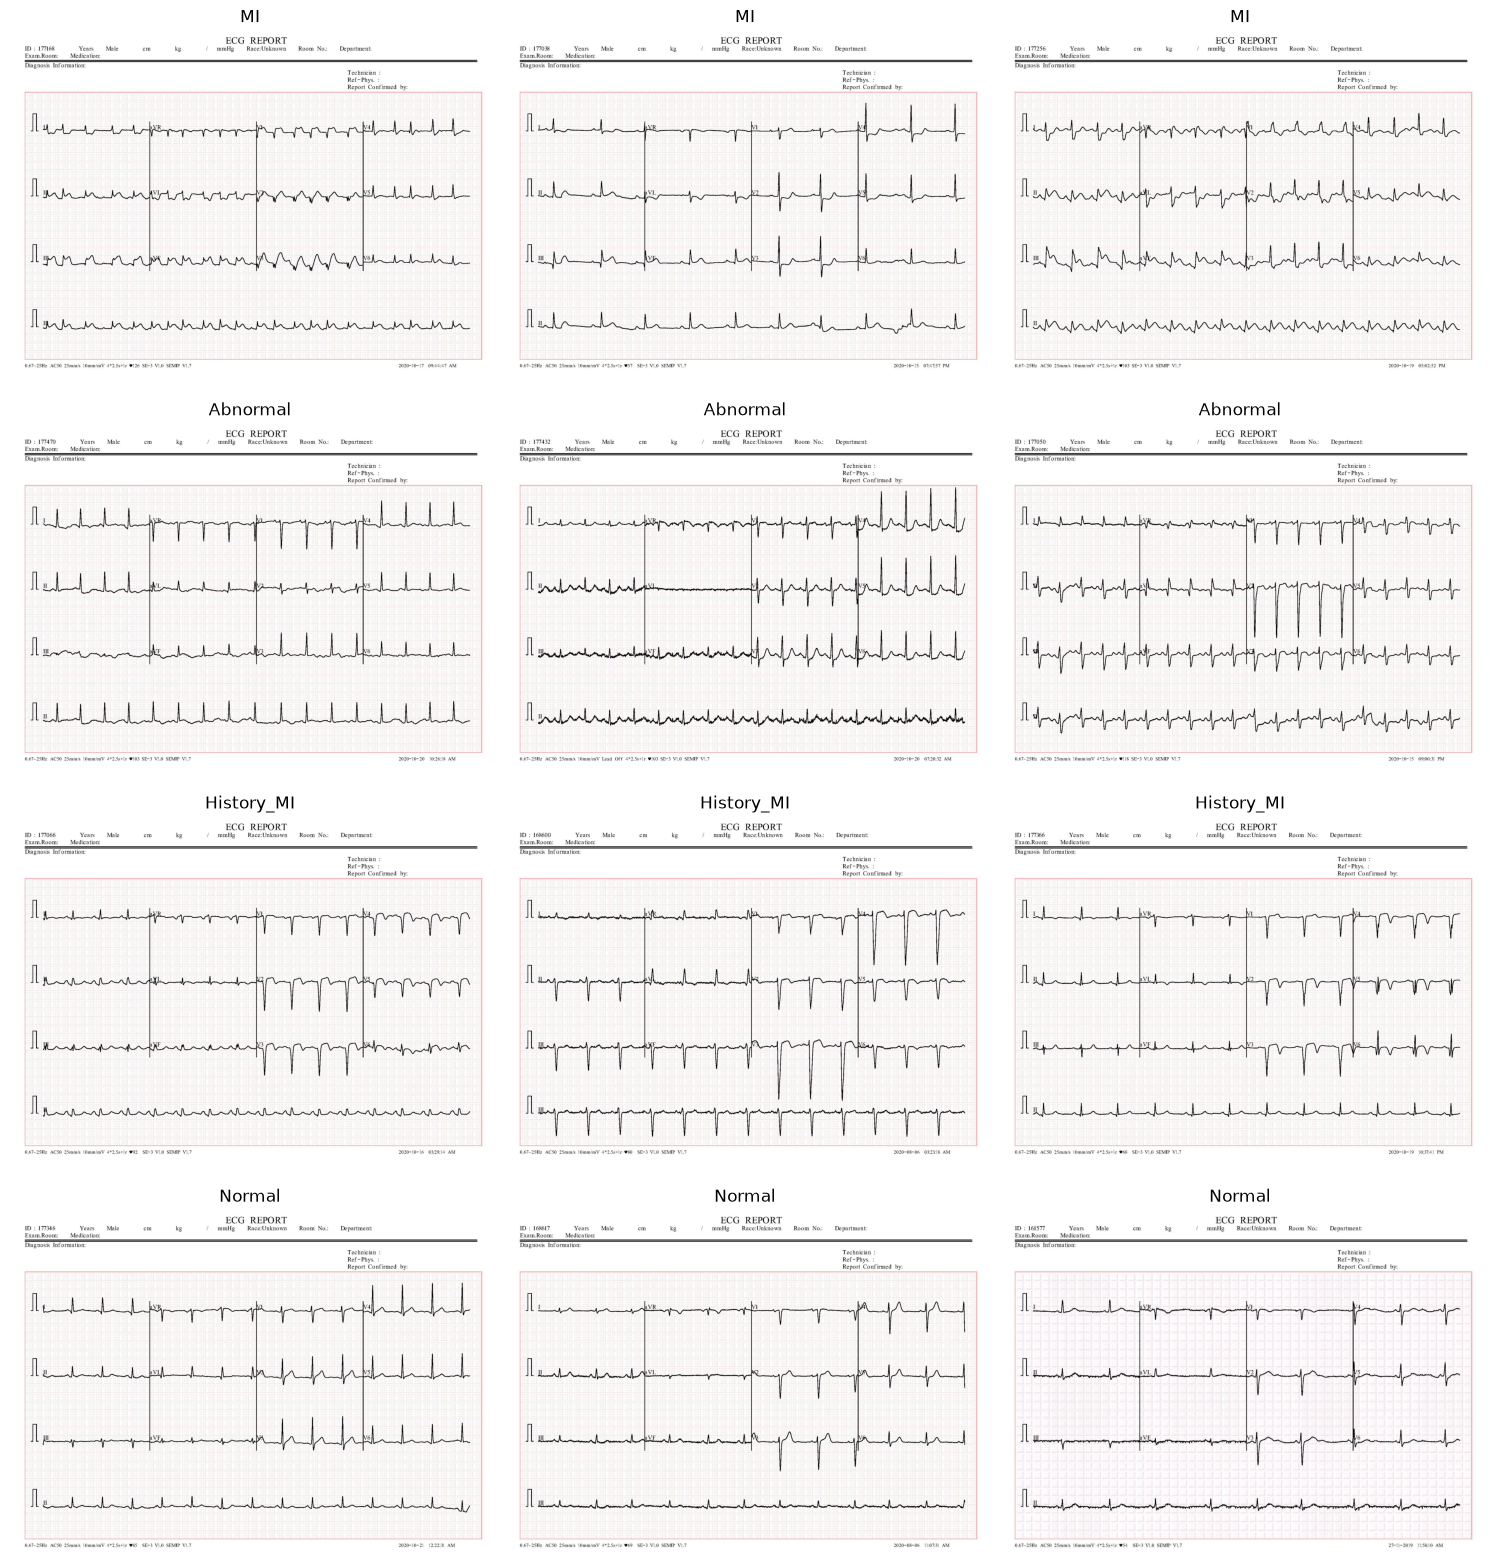

In [27]:
fig, axes = plt.subplots(
    4,
    3,
    figsize=(15, 16)
)

for row, class_name in enumerate(CLASS_TO_LABEL.keys()):

    class_samples = (
        train_full_df[
            train_full_df["class_name"] == class_name
        ]
        .sample(
            n=3,
            random_state=SEED
        )
    )

    for col, (_, sample) in enumerate(class_samples.iterrows()):

        with Image.open(sample["image_path"]) as img:

            axes[row, col].imshow(img)
            axes[row, col].axis("off")
            axes[row, col].set_title(class_name)

plt.tight_layout()
plt.show()

In [28]:
duplicate_names = (
    train_full_df["image_path"]
    .apply(lambda x: Path(x).name)
    .duplicated()
    .sum()
)

print("Duplicate filenames in train:", duplicate_names)

Duplicate filenames in train: 0


In [29]:
train_df, val_df = train_test_split(
    train_full_df,
    test_size=0.15,
    random_state=SEED,
    stratify=train_full_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 2569
Validation: 454
Test: 928


In [30]:
train_df["class_name"].value_counts()

class_name
MI            812
Normal        724
Abnormal      594
History_MI    439
Name: count, dtype: int64

In [31]:
val_df["class_name"].value_counts()

class_name
MI            144
Normal        128
Abnormal      105
History_MI     77
Name: count, dtype: int64

In [32]:
comparison = pd.DataFrame({
    "Original Train": train_full_df["class_name"]
        .value_counts(normalize=True),

    "New Train": train_df["class_name"]
        .value_counts(normalize=True),

    "Validation": val_df["class_name"]
        .value_counts(normalize=True),

    "Test": test_df["class_name"]
        .value_counts(normalize=True)
})

comparison

,Original Train,New Train,Validation,Test
class_name,,,,
Abnormal,0.231227,0.231218,0.231278,0.251078
History_MI,0.170691,0.170884,0.169604,0.185345
MI,0.316242,0.316076,0.317181,0.257543
Normal,0.281839,0.281822,0.281938,0.306034


In [33]:
train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

In [34]:
columns = [
    "image_path",
    "label",
    "class_name",
    "split"
]

train_df = train_df[columns]
val_df = val_df[columns]
test_df = test_df[columns]

In [35]:
train_csv_path = SPLIT_DIR / "train.csv"
val_csv_path = SPLIT_DIR / "val.csv"
test_csv_path = SPLIT_DIR / "test.csv"

train_df.to_csv(
    train_csv_path,
    index=False
)

val_df.to_csv(
    val_csv_path,
    index=False
)

test_df.to_csv(
    test_csv_path,
    index=False
)

print("Saved:")
print(train_csv_path)
print(val_csv_path)
print(test_csv_path)

Saved:
E:\Academia\archive\ECG_MI_Project\data\splits\train.csv
E:\Academia\archive\ECG_MI_Project\data\splits\val.csv
E:\Academia\archive\ECG_MI_Project\data\splits\test.csv


In [36]:
pd.read_csv(train_csv_path).head()

,image_path,label,class_name,split
0,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,3,Normal,train
1,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,1,Abnormal,train
2,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,0,MI,train
3,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,1,Abnormal,train
4,E:\Academia\archive\ECG_MI_Project\ECG_DATA\tr...,3,Normal,train


In [37]:
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

print(
    "Train-Val overlap:",
    len(train_paths.intersection(val_paths))
)

print(
    "Train-Test overlap:",
    len(train_paths.intersection(test_paths))
)

print(
    "Val-Test overlap:",
    len(val_paths.intersection(test_paths))
)

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [38]:
class_counts = (
    train_df["label"]
    .value_counts()
    .sort_index()
)

total_samples = class_counts.sum()
num_classes = len(class_counts)

class_weights = (
    total_samples /
    (num_classes * class_counts)
)

class_weights

label
0    0.790948
1    1.081229
2    1.462984
3    0.887086
Name: count, dtype: float64

In [39]:
class_weight_df = pd.DataFrame({
    "label": class_counts.index,
    "class_name": [
        LABEL_TO_CLASS[i]
        for i in class_counts.index
    ],
    "count": class_counts.values,
    "weight": class_weights.values
})

class_weight_df

,label,class_name,count,weight
0,0,MI,812,0.790948
1,1,Abnormal,594,1.081229
2,2,History_MI,439,1.462984
3,3,Normal,724,0.887086


In [40]:
class_weight_path = SPLIT_DIR / "class_weights.csv"

class_weight_df.to_csv(
    class_weight_path,
    index=False
)

print("Saved:", class_weight_path)

Saved: E:\Academia\archive\ECG_MI_Project\data\splits\class_weights.csv


In [41]:
summary = pd.DataFrame({
    "Train": train_df["class_name"].value_counts(),
    "Validation": val_df["class_name"].value_counts(),
    "Test": test_df["class_name"].value_counts()
}).fillna(0).astype(int)

summary.loc["TOTAL"] = summary.sum()

summary

,Train,Validation,Test
class_name,,,
Abnormal,594,105,233
History_MI,439,77,172
MI,812,144,239
Normal,724,128,284
TOTAL,2569,454,928


## Dataset Analysis Summary

- The dataset contains four classes:
  - MI
  - Abnormal heartbeat
  - History of MI
  - Normal

- The original dataset contains separate train and test folders.

- The original train folder was divided into:
  - 85% training
  - 15% validation

- The original test folder was preserved for final evaluation.

- The dataset shows moderate class imbalance.

- Class weights were calculated for later use with weighted cross-entropy loss.

- ECG image dimensions were inspected before model preprocessing.

The next step is to build the PyTorch dataset loader in `src/dataset.py`.